# Load the clean data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv(r"C:\Users\YADVEER\OneDrive\Desktop\churn-analysis\data\telco_clean.csv")


# Churn rate by category

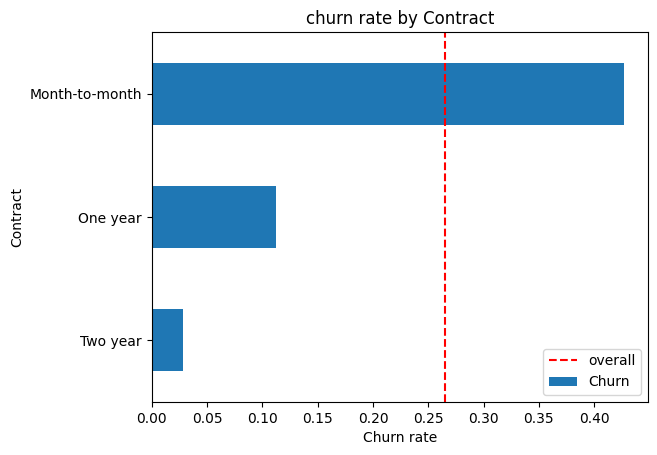

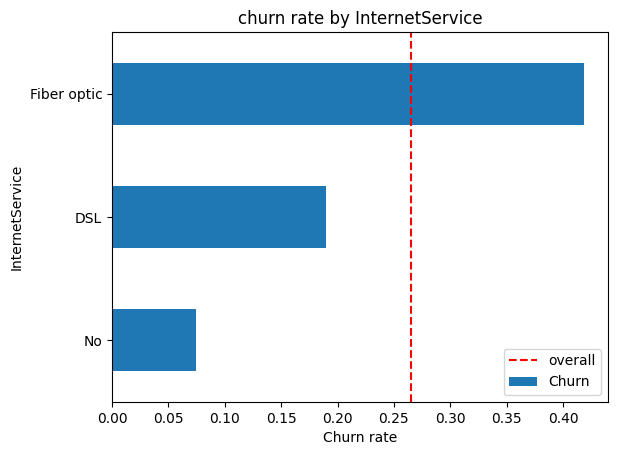

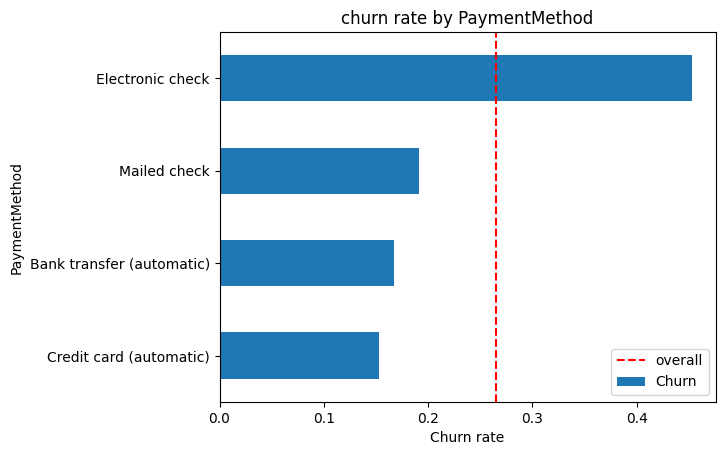

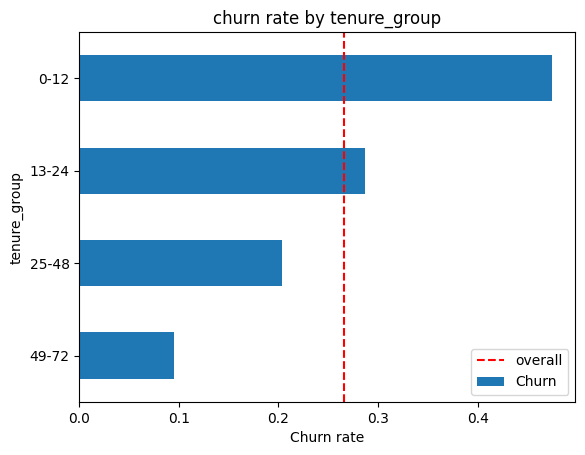

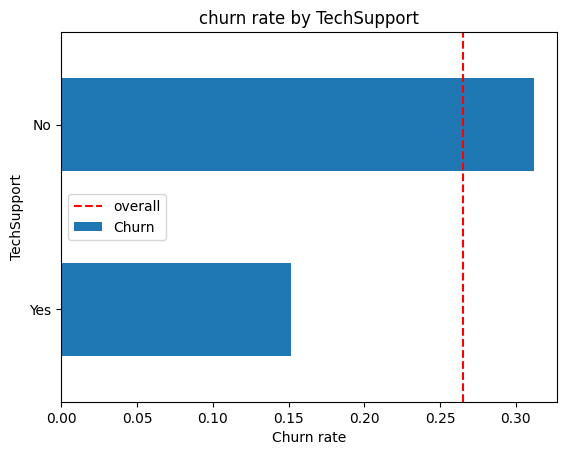

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv(r"C:\Users\YADVEER\OneDrive\Desktop\churn-analysis\data\telco_clean.csv")
columns = ["Contract", "InternetService", "PaymentMethod",
           "tenure_group", "TechSupport"]
for col in columns:
    rate=df.groupby(col)['Churn'].mean().sort_values()
    rate.plot(kind="barh" ,title = f"churn rate by {col}" )
    plt.axvline(df['Churn'].mean(),color="red",linestyle="--",label="overall")
    plt.legend()
    plt.xlabel("Churn rate")
    plt.savefig(f"../reports/churn_by_{col}", bbox_inches="tight")
    plt.show()

# Tenure distribution

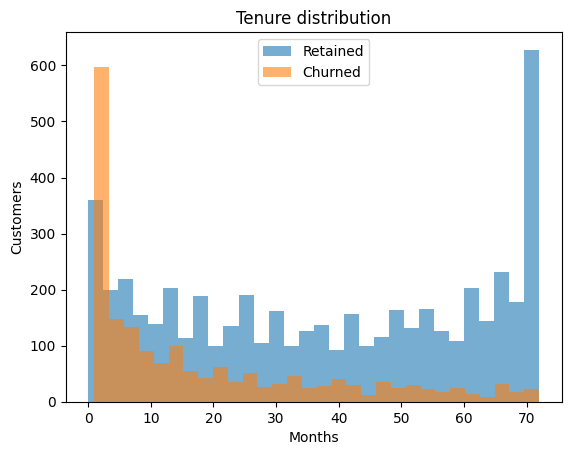

In [3]:
plt.hist(df[df.Churn==0]["tenure"], bins=30, alpha=.6, label="Retained")
plt.hist(df[df.Churn==1]["tenure"], bins=30, alpha=.6, label="Churned")
plt.legend(); plt.title("Tenure distribution"); plt.xlabel("Months"); plt.ylabel("Customers")
plt.savefig("../reports/tenure_distribution.png", bbox_inches="tight")
plt.show()

## Insights

### 1. Contract
- **What I see:** Month-to-month customers churn at about 43%, well above the 26.5% overall average. One-year is about 11% and two-year is about 3%.
- **Why it matters:** Customers who are not locked in leave easily. Contract length is the strongest churn lever.

### 2. Internet Service
- **What I see:** Fiber optic customers churn at about 42%, more than double DSL (about 19%). Customers with no internet churn least (about 7%).
- **Why it matters:** Fiber is the premium product yet loses the most customers, which points to a price, quality, or competition issue worth investigating.

### 3. Payment Method
- **What I see:** Electronic check payers churn at about 45%. Mailed check is about 19%, and the automatic methods (bank transfer, credit card) are lowest at about 15-17%.
- **Why it matters:** Automatic payment goes with lower churn. Nudging electronic check users to autopay is a low-cost retention action.

### 4. Tech Support
- **What I see:** Customers without tech support churn at about 31%, versus about 15% for those with it.
- **Why it matters:** Customers with support are about half as likely to leave. Bundling or promoting tech support could help retention (correlation, not proof of cause).

### 5. Tenure Group
- **What I see:** Churn is highest in the first 12 months (about 47%) and falls steadily to under 10% for customers with 4+ years.
- **Why it matters:** The first year is the danger zone, so retention effort should focus on new customers.

### 6. Tenure Distribution
- **What I see:** Churned customers are concentrated in the first few months, with a spike of about 600 at the very start. Retained customers are spread across all tenures, with a large group at 70+ months.
- **Why it matters:** Most churn happens early. Customers who survive the first months tend to stay long term.

### 7. Correlation
- **What I see:** Tenure has a negative relationship with churn, and monthly charges has a weaker positive one (replace with the exact values from your correlation output).
- **Why it matters:** Longer-tenured customers are less likely to leave, and higher bills slightly raise the risk. Both will feed the risk score in Step 6.

## Key Takeaways
1. Contract type is the strongest driver: month-to-month ~43% vs two-year ~3%.
2. New customers (0-12 months) churn at ~47%, the highest of any tenure group.
3. Fiber optic customers churn at ~42%, more than double DSL.
4. Electronic check payers churn at ~45%, versus ~15-17% for automatic payment.
5. Customers without tech support churn about twice as much as those with it.
